# Análisis y limpieza de datos climatológicos



## 1. Cargar las librerías y revisar el archivo




In [30]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

archivo = Path("25001.txt")
print("¿Se encontró el archivo?", archivo.exists())

with open(archivo, "r", encoding="utf-8-sig", errors="replace") as f:
    for i in range(12):
        print(f.readline().rstrip())


¿Se encontró el archivo? True
CNA-SMN-CG-GMC-SMAA-CLIMATOLOGIA
BASE DE DATOS CLIMATOLOGICA
DATOS DISPONIBLES EN LA BASE DE DATOS A MARZO 2020;CON LA INFORMACION SUMINISTRADA POR LAS OFICINAS REGIONALES

ESTACION  : 25001
NOMBRE    : ACATITAN
ESTADO    : SINALOA
MUNICIPIO : SAN IGNACIO
SITUACI�N : OPERANDO
ORGANISMO : CONAGUA-DGE
CVE-OMM   : Nulo
LATITUD   : 024.097�


## 2. Leer las filas diarias

La función siguiente revisa cada línea. Si comienza con una fecha, separa la fecha de sus cuatro mediciones. `Nulo` se cambia por `NaN`, que pandas reconoce como un dato faltante. Después convertimos la fecha y las mediciones a sus tipos adecuados.


In [31]:
columnas = ["fecha", "precip_mm", "evap_mm", "tmax_c", "tmin_c"]

def cargar_datos(ruta):
    filas = []
    with open(ruta, "r", encoding="utf-8-sig", errors="replace") as f:
        for linea in f:
            partes = linea.split()
            # Las fechas del archivo comienzan con día/mes/año, por ejemplo 01/01/1961
            if partes and partes[0].count("/") == 2:
                if len(partes) == 5:
                    filas.append(partes)

    datos = pd.DataFrame(filas, columns=columnas)
    datos["fecha"] = pd.to_datetime(datos["fecha"], format="%d/%m/%Y")
    for col in columnas[1:]:
        datos[col] = pd.to_numeric(datos[col].replace("Nulo", np.nan))
    return datos

datos = cargar_datos(archivo)
print("Cantidad de registros:", len(datos))
print("Primera fecha:", datos["fecha"].min())
print("Última fecha:", datos["fecha"].max())
datos.head()


Cantidad de registros: 19574
Primera fecha: 1961-01-01 00:00:00
Última fecha: 2018-07-31 00:00:00


,fecha,precip_mm,evap_mm,tmax_c,tmin_c
0,1961-01-01,0.0,NaN,25.0,13.0
1,1961-01-02,0.0,NaN,27.5,14.0
2,1961-01-03,0.0,NaN,31.0,11.0
3,1961-01-04,0.0,NaN,32.0,13.0
4,1961-01-05,0.0,NaN,29.0,14.0


## 3. Revisar los datos

`shape` muestra cuántas filas y columnas hay. `dtypes` indica el tipo de cada columna. Revisar esto ayuda a confirmar que las fechas y mediciones se puedan analizar correctamente.


In [32]:
print("Filas y columnas:", datos.shape)
print(datos.dtypes)
datos.head(10)


Filas y columnas: (19574, 5)
fecha        datetime64[us]
precip_mm           float64
evap_mm             float64
tmax_c              float64
tmin_c              float64
dtype: object


,fecha,precip_mm,evap_mm,tmax_c,tmin_c
0,1961-01-01,0.0,NaN,25.0,13.0
1,1961-01-02,0.0,NaN,27.5,14.0
2,1961-01-03,0.0,NaN,31.0,11.0
3,1961-01-04,0.0,NaN,32.0,13.0
4,1961-01-05,0.0,NaN,29.0,14.0
5,1961-01-06,0.0,NaN,24.0,14.5
6,1961-01-07,0.0,NaN,28.5,10.0
7,1961-01-08,0.0,NaN,32.0,12.0
8,1961-01-09,0.0,NaN,33.5,11.0
9,1961-01-10,0.0,NaN,32.5,9.5


## 4. Contar los datos faltantes

Contamos los faltantes antes de rellenarlos. Primero por columna y luego por fecha. Al sumar por fila (`axis=1`) obtenemos cuántas mediciones faltan en cada día.


In [33]:
mediciones = columnas[1:]
print("Faltantes por columna:")
print(datos[mediciones].isna().sum())

faltantes_fecha = datos[["fecha"]].copy()
faltantes_fecha["total_faltantes"] = datos[mediciones].isna().sum(axis=1)
print("\nFechas con datos faltantes:", (faltantes_fecha["total_faltantes"] > 0).sum())
faltantes_fecha[faltantes_fecha["total_faltantes"] > 0].head(10)


Faltantes por columna:
precip_mm     40
evap_mm      272
tmax_c         5
tmin_c         6
dtype: int64

Fechas con datos faltantes: 312


,fecha,total_faltantes
0,1961-01-01,1
1,1961-01-02,1
2,1961-01-03,1
3,1961-01-04,1
4,1961-01-05,1
5,1961-01-06,1
6,1961-01-07,1
7,1961-01-08,1
8,1961-01-09,1
9,1961-01-10,1


Cada renglón de `faltantes_fecha` corresponde a un día. El número en `total_faltantes` indica cuántas de sus cuatro mediciones estaban vacías.


## 5. Rellenar faltantes con la media

La instrucción pide reemplazar los faltantes con la media de su columna. Calculamos la media de cada medición y usamos `fillna()` para completar los espacios. Conservamos `datos` como tabla original y guardamos el resultado en `datos_limpios`.


In [34]:
datos_limpios = datos.copy()
medias = datos_limpios[mediciones].mean()
datos_limpios[mediciones] = datos_limpios[mediciones].fillna(medias)

print("Medias utilizadas:")
print(medias)
print("\nFaltantes después de limpiar:")
print(datos_limpios[mediciones].isna().sum())


Medias utilizadas:
precip_mm     2.217452
evap_mm       4.882157
tmax_c       34.468808
tmin_c       16.657420
dtype: float64

Faltantes después de limpiar:
precip_mm    0
evap_mm      0
tmax_c       0
tmin_c       0
dtype: int64


### Comparación antes y después de rellenar

La tabla original (`datos`) conserva los nulos. La tabla limpia (`datos_limpios`) contiene la media en esas mismas posiciones. Primero veremos algunas filas que tenían al menos un faltante y luego cuántos valores se rellenaron en cada medición. Así se puede comparar el dato faltante con el valor que se usó para reemplazarlo.


In [35]:
filas_con_nulos = datos[mediciones].isna().any(axis=1)

antes = datos.loc[filas_con_nulos, ["fecha"] + mediciones].head().copy()
antes = antes.rename(columns={col: col + "_antes" for col in ["fecha"] + mediciones})
despues = datos_limpios.loc[filas_con_nulos, mediciones].head().add_suffix("_despues")
comparacion = pd.concat([antes.reset_index(drop=True), despues.reset_index(drop=True)], axis=1)
display(comparacion)

valores_rellenados = datos[mediciones].isna().sum()
print("Cantidad de valores reemplazados por columna:")
print(valores_rellenados)


,fecha_antes,precip_mm_antes,evap_mm_antes,tmax_c_antes,tmin_c_antes,precip_mm_despues,evap_mm_despues,tmax_c_despues,tmin_c_despues
0,1961-01-01,0.0,NaN,25.0,13.0,0.0,4.882157,25.0,13.0
1,1961-01-02,0.0,NaN,27.5,14.0,0.0,4.882157,27.5,14.0
2,1961-01-03,0.0,NaN,31.0,11.0,0.0,4.882157,31.0,11.0
3,1961-01-04,0.0,NaN,32.0,13.0,0.0,4.882157,32.0,13.0
4,1961-01-05,0.0,NaN,29.0,14.0,0.0,4.882157,29.0,14.0


Cantidad de valores reemplazados por columna:
precip_mm     40
evap_mm      272
tmax_c         5
tmin_c         6
dtype: int64


### Ejemplo sencillo

En esta lista falta un valor. La media de 20 y 24 es 22, por lo que ese valor se usa para rellenar el espacio. En los datos de la estación hacemos lo mismo por separado para cada medición.


In [36]:
ejemplo = pd.Series([20, np.nan, 24])
ejemplo = ejemplo.fillna(ejemplo.mean())
print(ejemplo)


0    20.0
1    22.0
2    24.0
dtype: float64


## 6. Resumen estadístico

`describe()` presenta el conteo, promedio, desviación estándar, mínimo, cuartiles y máximo. Esto ayuda a conocer los valores y la variabilidad de cada medición.


In [37]:
datos_limpios[mediciones].describe()


,precip_mm,evap_mm,tmax_c,tmin_c
count,19574.000000,19574.000000,19574.000000,19574.000000
mean,2.217452,4.882157,34.468808,16.657420
std,9.006565,2.263447,3.429615,6.247648
min,0.000000,0.000000,18.000000,-2.500000
25%,0.000000,3.200000,32.500000,11.000000
50%,0.000000,4.600000,35.000000,16.500000
75%,0.000000,6.400000,37.000000,23.000000
max,217.400000,15.600000,45.500000,29.000000


## 7. Gráficas de los cambios en el tiempo

En esta sección hacemos una gráfica para cada medición. Usamos `plot()` de pandas, que crea las gráficas directamente desde la tabla. `subplots=True` pone cada medición en su propio panel para que no se mezclen sus escalas.

- El eje horizontal (**x**) muestra las fechas, desde 1961 hasta 2018.
- El eje vertical (**y**) muestra el valor de la medición indicada en el título de cada panel. La lluvia y evaporación están en milímetros; las temperaturas están en grados Celsius.
- En precipitación, muchos días están cerca de cero porque no llovió o llovió muy poco. Los picos altos representan días de lluvia intensa.
- En temperatura, los cambios que se repiten a lo largo del tiempo pueden reflejar temporadas del año.

La gráfica usa `datos_limpios`, así que también aparecen los valores que rellenamos con la media. Esos puntos son estimaciones y pueden hacer que algunos cambios se vean más suaves. Como hay muchos días, la gráfica puede verse muy densa; sirve para observar el panorama general, no para leer con precisión cada fecha.

En la gráfica diaria de precipitación, los picos altos son candidatos a eventos extremos (días de lluvia intensa). Para ubicar el mayor valor y su fecha, revisamos también la tabla de los cinco días con más lluvia. Un valor alto no es automáticamente un error: se debe contrastar con el registro original o con información de la estación.


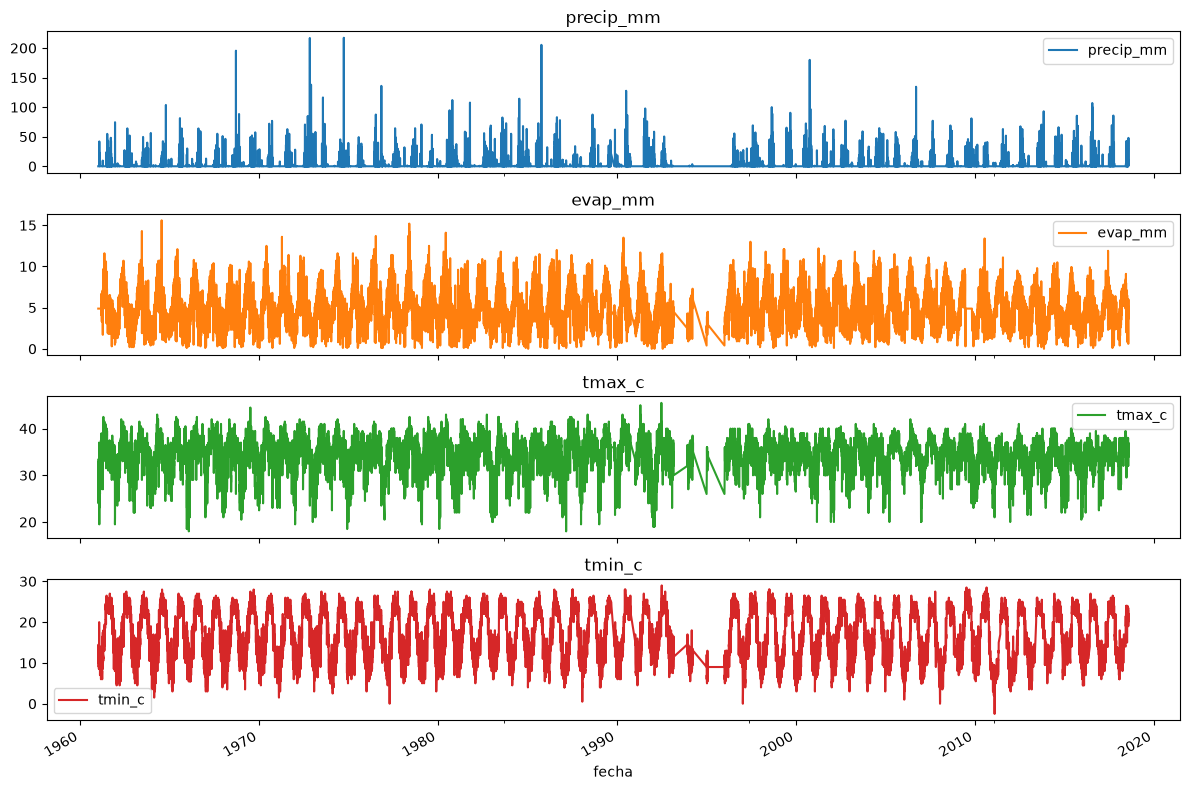

,fecha,precip_mm
5013,1974-09-23,217.4
4319,1972-10-29,217.0
9015,1985-10-08,205.4
2811,1968-09-12,195.5
13398,2000-10-06,180.0


In [38]:
datos_limpios.plot(
    x="fecha",
    y=mediciones,
    subplots=True,
    figsize=(12, 8),
    title=mediciones
)
plt.tight_layout()
plt.show()


# Revisar las cinco fechas con mayor precipitación
datos_limpios[["fecha", "precip_mm"]].sort_values(
    "precip_mm", ascending=False
).head()


## 8. Histogramas: forma y distribución de los datos

Un histograma agrupa los valores en intervalos. La altura de cada barra indica cuántos días tienen valores dentro de ese intervalo. Aquí hacemos un histograma para cada medición.

Al observarlos, podemos fijarnos en lo siguiente:

- **Dónde se concentran los datos:** las barras más altas muestran los intervalos más frecuentes.
- **Sesgo:** si la mayoría de las barras está hacia un lado y hay una cola larga hacia el otro, la distribución está sesgada. Una cola hacia la derecha indica sesgo positivo; una cola hacia la izquierda, sesgo negativo.
- **Valores extremos:** barras aisladas lejos del grupo principal pueden señalar valores inusuales que conviene revisar. No necesariamente son errores: podrían ser eventos reales, como un día de lluvia intensa.
- **Forma:** una distribución más equilibrada a ambos lados se considera más simétrica. Los datos reales no tienen que formar una campana perfecta para ser útiles.

En este conjunto, es razonable esperar muchos días con precipitación baja o igual a cero y pocos días con lluvia alta. Eso produce una cola hacia la derecha y no significa por sí solo que los datos sean malos. Para decidir si hay un error, hay que revisar el registro original, el contexto y las unidades. Además, los valores que rellenamos con la media también aparecen en los histogramas y pueden cambiar un poco su forma.

Un histograma ayuda a detectar colas largas o valores aislados, pero no marca por sí solo cuáles son atípicos. Para complementar la revisión usamos diagramas de caja.


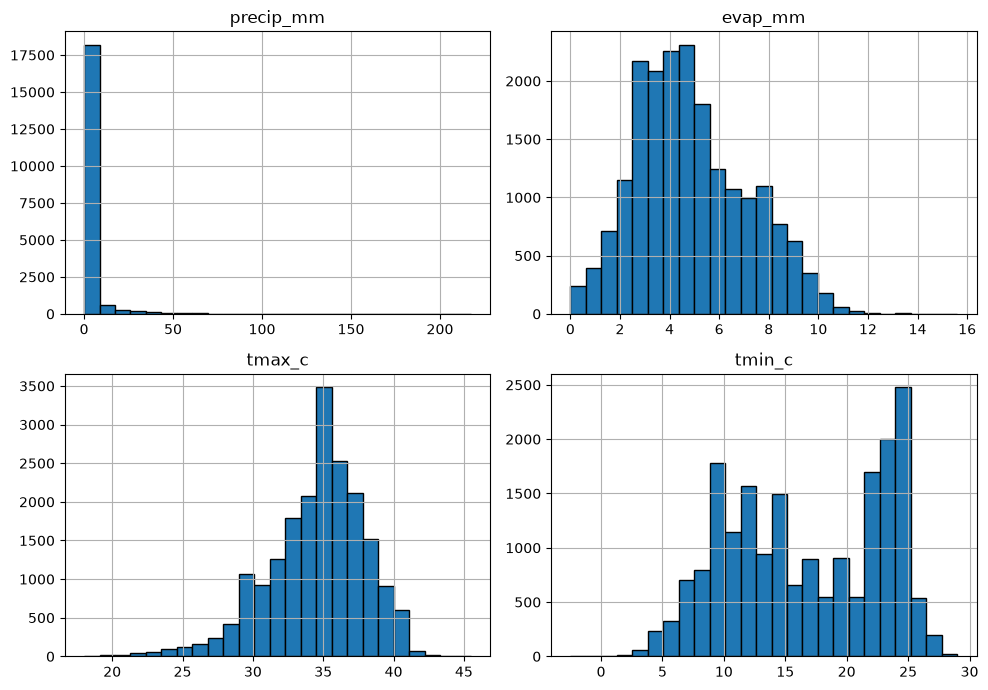

In [39]:
datos_limpios[mediciones].hist(figsize=(10, 7), bins=25, edgecolor="black")
plt.tight_layout()
plt.show()


### Diagrama de caja y bigotes: comparar la distribución

El diagrama de caja y bigotes resume la distribución de cada medición y ayuda a comparar sus valores típicos y su dispersión.

- **Línea dentro de la caja:** la mediana, o valor central. La mitad de los datos queda por debajo y la otra mitad por encima.
- **Caja:** va del primer cuartil (25%) al tercer cuartil (75%). Ahí se encuentra el 50% central de los valores. La altura de la caja muestra cuánto varían esos valores centrales.
- **Bigotes:** se extienden desde la caja hasta los valores más alejados que todavía están dentro del rango esperado. En este gráfico llegan hasta 1.5 veces el rango intercuartílico (la altura de la caja).
- **Puntos fuera de los bigotes:** son posibles valores atípicos porque están más alejados que la mayoría. No son automáticamente errores; por ejemplo, un pico de lluvia puede ser un evento real.

Una caja o un bigote más largo indica mayor variación. Si la mediana no queda al centro de la caja o un bigote es mucho más largo que el otro, la distribución puede estar sesgada. Como las cuatro mediciones usan unidades y escalas distintas, cada panel tiene su propia escala vertical; comparamos la forma de cada distribución, no las alturas entre variables.


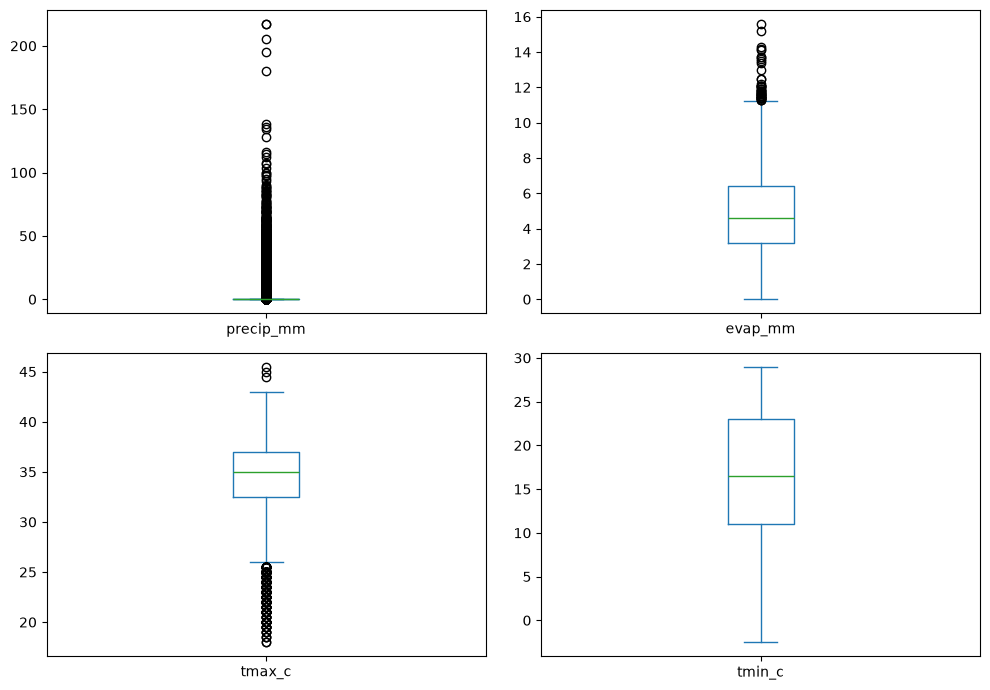

In [40]:
datos_limpios[mediciones].plot(
    kind="box",
    subplots=True,
    layout=(2, 2),
    figsize=(10, 7),
    sharey=False
)
plt.tight_layout()
plt.show()


## 9. Correlación

La correlación muestra si dos mediciones tienden a cambiar juntas. Sus valores van de -1 a 1:

- Cerca de **1**: relación positiva; ambas variables suelen aumentar juntas.
- Cerca de **-1**: relación negativa; cuando una aumenta, la otra suele bajar.
- Cerca de **0**: poca relación lineal.

Usamos `.corr()` de pandas para calcular la correlación entre las mediciones. La tabla compara cada variable con las demás; los valores `1.00` en la diagonal son cada variable comparada consigo misma y no se consideran al comparar variables distintas.

En estos datos, la relación más fuerte entre variables distintas es **evaporación y temperatura máxima** (aprox. **0.63**), una relación positiva moderada. La más débil es **precipitación y temperatura máxima** (aprox. **-0.06**), muy cercana a cero. Esto significa que en este conjunto casi no muestran una relación lineal. Correlación no demuestra que una variable cause cambios en otra.

### Mapa de calor

El mapa muestra la misma tabla con colores: cada cuadro corresponde a una pareja de variables y su número es la correlación. Los tonos cálidos representan valores positivos y los fríos valores negativos; los valores cercanos a cero tienen colores más neutros. Observa los cuadros fuera de la diagonal para comparar mediciones diferentes.


In [41]:
correlaciones = datos_limpios[mediciones].corr()
correlaciones.round(2)


,precip_mm,evap_mm,tmax_c,tmin_c
precip_mm,1.00,-0.07,-0.06,0.24
evap_mm,-0.07,1.00,0.63,0.14
tmax_c,-0.06,0.63,1.00,0.40
tmin_c,0.24,0.14,0.40,1.00


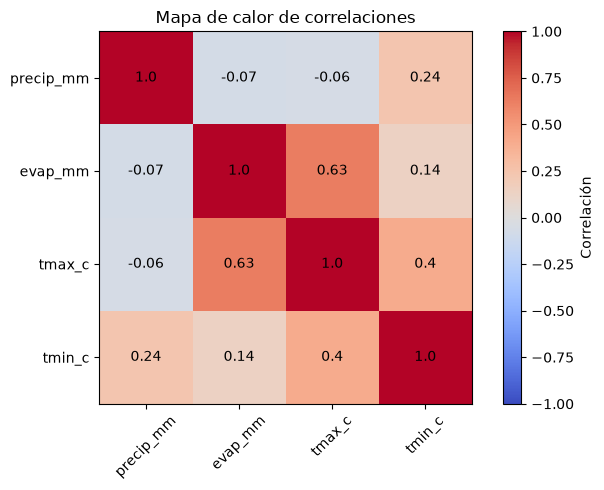

In [42]:
plt.figure(figsize=(7, 5))
plt.imshow(correlaciones, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlación")
plt.xticks(range(len(mediciones)), mediciones, rotation=45)
plt.yticks(range(len(mediciones)), mediciones)

# Mostrar el valor numérico dentro de cada cuadro
for fila in range(len(mediciones)):
    for columna in range(len(mediciones)):
        plt.text(columna, fila, round(correlaciones.iloc[fila, columna], 2),
                 ha="center", va="center")

plt.title("Mapa de calor de correlaciones")
plt.tight_layout()
plt.show()


## 10. Conclusiones

El archivo contiene **19,574 registros diarios**, de 1961 a 2018. A partir de los conteos, las tablas y las gráficas, se observa lo siguiente:

- **Columna más completa:** temperatura máxima (`tmax_c`) tuvo solo **5 valores faltantes**; temperatura mínima tuvo 6. Por eso, temperatura máxima fue la columna con menos faltantes y la más completa en este conjunto. Esto habla de integridad, no significa que sea la medición más importante o que todos sus valores sean correctos.
- **Columna con más faltantes:** evaporación (`evap_mm`) tuvo **272 faltantes**. Precipitación tuvo 40. En total se reemplazaron **323 valores**, distribuidos en **312 fechas** con al menos una medición ausente.
- **Efecto del llenado:** los valores vacíos se reemplazaron con la media de su propia columna: precipitación **2.22 mm**, evaporación **4.88 mm**, temperatura máxima **34.47 °C** y temperatura mínima **16.66 °C**. La tabla comparativa permite ver ejemplos originales como `NaN` junto con el valor rellenado. Mantuvimos `datos` para conservar los datos originales y `datos_limpios` para el análisis. El relleno permite usar las funciones estadísticas y hacer gráficas completas, pero los valores imputados son estimaciones y pueden suavizar variaciones reales.
- **Lo que muestran las gráficas:** en el histograma de precipitación, los valores se concentran en cero y unos pocos días tienen lluvia alta; esto produce un sesgo hacia la derecha. El máximo registrado fue **217.4 mm el 23/09/1974**, un pico que conviene revisar como evento extremo, aunque no necesariamente sea un error. El diagrama de caja ayuda a localizar estos valores alejados del grupo central.
- **Relación entre variables:** evaporación y temperatura máxima presentan la correlación más alta entre mediciones distintas (**0.63**, positiva moderada). Precipitación y temperatura máxima tienen la más cercana a cero (**-0.06**), así que muestran poca relación lineal en este conjunto.

En conjunto, la exploración muestra que la limpieza permitió trabajar con todas las fechas, pero es importante distinguir los datos observados de los valores rellenados y revisar los eventos extremos en su contexto antes de considerarlos errores.

